# Q-learning no Lago Congelado com taxa de aprendizado decrescente

Atividade de **DIM0126 - Inteligência Artificial para Jogos I** (aula 3.5, aprendizado por reforço). Versão individual da Luisa.

Exercício proposto nos slides:

1. Experimentar o Q-learning no Lago Congelado (`FrozenLake-v1`) usando o notebook do Colab disponibilizado;
2. Testar o Q-learning variando os hiperparâmetros (taxa de aprendizado, exploração, ...);
3. Testar o Q-learning em outros cenários do Toy Text.

O agente parte do `FrozenLakeAgent` do notebook da disciplina (Q-table, ε-greedy com decaimento linear, avaliação periódica
da política gulosa) e reaproveita o esqueleto do notebook do colega (`../qlearning_toy_text.ipynb`: `Config`, 5 sementes,
teste guloso a cada 25 episódios). Para os experimentos não ficarem iguais, o foco aqui é **um eixo que o colega não
explorou: a taxa de aprendizado α deixar de ser constante e diminuir ao longo do treino.**

| Tema | O colega usou | Aqui |
|------|---------------|------|
| α | constante (0.01, 0.1, 0.5, 0.9) | **decrescente**: por visitas, $\alpha = 1/(1+N(s,a))^\omega$, com e sem piso, e por episódio (linear de 0.5 a 0.01) |
| Mapa | 8x8 aleatório (`p=0.9`, semente 9) e 4x4 padrão | **`FrozenLake8x8-v1` padrão** e um 8x8 aleatório com **`p=0.8`** (mais buracos) |
| Treino no escorregadio | 5000 episódios (20000 em um teste) | **20000 episódios** em todas as configurações |
| Métricas | sucesso da política gulosa | sucesso, **erro da Q-table contra o Q\* exato** e **quantos estados trocam de ação** entre testes (estabilidade) |

γ = 0.95 e a exploração (ε de 0.5 a 0.1, linear) ficam iguais à configuração base, para que só α mude.

**Pergunta:** no gelo escorregadio o alvo $r + \gamma \max_{a'} Q(s',a')$ é ruidoso (o mesmo par (s, a) leva a estados
diferentes). Com α constante a Q-table nunca para de oscilar em torno do valor certo; a teoria (condições de Robbins-Monro:
$\sum_t \alpha_t = \infty$ e $\sum_t \alpha_t^2 < \infty$) diz que α decrescente faz ela convergir. Isso aparece na prática,
em 20000 episódios? E qual ritmo de decaimento funciona?

## 1. Setup

In [1]:
import importlib.util
if importlib.util.find_spec("gymnasium") is None:  # Colab sem gymnasium
    get_ipython().run_line_magic("pip", "install -q gymnasium")

import os, time
from collections import deque
from dataclasses import replace

import gymnasium as gym
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

# o agente fica em agente_luisa.py para as sementes rodarem em paralelo (processos separados)
from agente_luisa import Config, QLearningAgent, q_otimo, rodar_lote

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False})
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)
print("gymnasium", gym.__version__, "| numpy", np.__version__, "| núcleos", os.cpu_count())

gymnasium 1.4.0 | numpy 2.1.0 | núcleos 12


## 2. Agente e programações de α

$$Q(s,a) \leftarrow Q(s,a) + \alpha_t \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]$$

O agente é o do notebook original (Q-table zerada, ε-greedy com ε de 0.5 a 0.1 em decaimento linear, alvo sem bootstrap
quando o episódio termina). A única mudança é **de onde vem $\alpha_t$** (`Config.alpha_modo`, ver `agente_luisa.py`):

| Modo | Fórmula | Ideia |
|------|---------|-------|
| `const` | $\alpha_t = \alpha$ | o original |
| `visitas` | $\alpha_t(s,a) = \max\left(\alpha_{\min},\ \dfrac{1}{(1 + N(s,a))^{\omega}}\right)$ | cada par tem sua própria taxa, que cai com o número $N(s,a)$ de atualizações já feitas nele |
| `episodio` | $\alpha_t = \alpha_0 - (\alpha_0 - \alpha_f)\,\dfrac{\text{episódio}}{\text{total}}$ | uma taxa global, que cai em linha reta de $\alpha_0 = 0.5$ a $\alpha_f = 0.01$ |

- Com $\omega = 1$ e sem piso, $Q(s,a)$ vira a **média simples** de todos os alvos já vistos naquele par. Parece ideal, mas
  os primeiros alvos foram calculados com a Q-table ainda zerada e pesam tanto quanto os últimos.
- Com $0.5 < \omega < 1$ a taxa cai mais devagar (média "esquecida"): ainda satisfaz Robbins-Monro, mas dá mais peso aos
  alvos recentes. Valores testados: 0.8 e 0.6.
- Com piso ($\alpha_{\min} = 0.05$) a taxa para de cair; deixa de convergir no sentido estrito, mas continua acompanhando
  alvos que mudam.
- O modo por episódio não diferencia pares muito e pouco visitados: o canto do mapa que quase nunca é visitado recebe
  a mesma taxa pequena do início do caminho.

Como comparação, três α constantes: 0.5 (base), 0.1 (o melhor do colega no escorregadio) e 0.02 (pequeno desde o início,
para separar "α pequeno" de "α que diminui").

In [2]:
BASE = Config()            # α = 0.5, γ = 0.95, ε 0.5 → 0.1 linear, 5000 episódios
SEEDS = [0, 1, 2, 3, 4]
EPISODIOS_ESC = 20000      # treino no gelo escorregadio

ALFAS = {
    "α = 0.5 (base)":            BASE,
    "α = 0.1":                   replace(BASE, alpha=0.1),
    "α = 0.02":                  replace(BASE, alpha=0.02),
    "α = 1/(1+N)":               replace(BASE, alpha_modo="visitas", omega=1.0),
    "α = 1/(1+N)^0.8":           replace(BASE, alpha_modo="visitas", omega=0.8),
    "α = 1/(1+N)^0.6":           replace(BASE, alpha_modo="visitas", omega=0.6),
    "α = max(0.05, 1/(1+N))":    replace(BASE, alpha_modo="visitas", omega=1.0, alpha_min=0.05),
    "α linear 0.5 → 0.01":       replace(BASE, alpha_modo="episodio", alpha=0.5, alpha_final=0.01),
}
CONSTANTES = [k for k, c in ALFAS.items() if c.alpha_modo == "const"]

# cores: paleta categórica fixa (uma cor por configuração, sempre a mesma em todas as figuras);
# α constante em tracejado, α decrescente em linha cheia (a cor não é a única pista)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COR = dict(zip(ALFAS, PALETA))
ESTILO = {k: ("--" if k in CONSTANTES else "-") for k in ALFAS}
BASE

Config(alpha=0.5, gamma=0.95, epsilon_inicial=0.5, epsilon_final=0.1, episodios=5000, freq_teste=25, episodios_teste=20, episodios_teste_final=500, alpha_modo='const', omega=1.0, alpha_min=0.0, alpha_final=0.01)

Como cada programação de α cai com o número de atualizações do par (para o modo por episódio, supondo 20000 episódios):

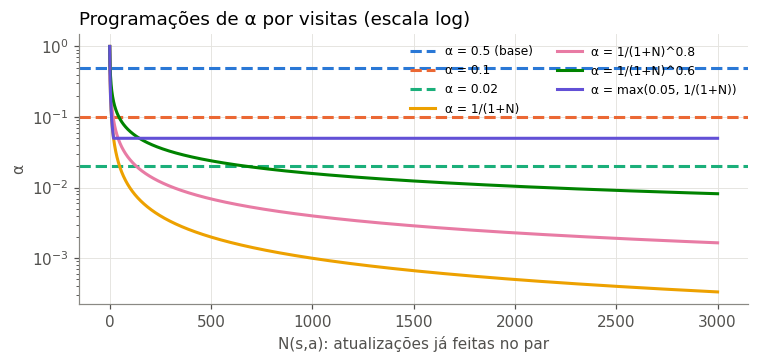

In [3]:
n = np.arange(0, 3001)
fig, ax = plt.subplots(figsize=(7, 3.4))
for rot, cfg in ALFAS.items():
    if cfg.alpha_modo == "visitas":
        y = np.maximum(cfg.alpha_min, 1 / (1 + n) ** cfg.omega)
        ax.plot(n, y, ESTILO[rot], color=COR[rot], lw=2, label=rot)
    elif cfg.alpha_modo == "const":
        ax.axhline(cfg.alpha, ls="--", color=COR[rot], lw=2, label=rot)
ax.set_yscale("log"); ax.set_xlabel("N(s,a): atualizações já feitas no par"); ax.set_ylabel("α")
ax.set_title("Programações de α por visitas (escala log)", loc="left")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig("figuras/exp0_programacoes_alpha.png", bbox_inches="tight"); plt.show()

## 3. Ambientes

### FrozenLake-v1 (Lago Congelado)

- **Estados**: a célula do grid, `linha * 8 + coluna` (64 estados).
- **Ações**: 4 (0 esquerda, 1 baixo, 2 direita, 3 cima).
- **Recompensa**: +1 ao chegar no objetivo `G`, 0 nos demais passos (inclusive ao cair num buraco `H`, que encerra o
  episódio). Limite de 100 passos.
- **`is_slippery=True`**: o agente só vai na direção escolhida com probabilidade 1/3; nas outras vezes desliza para uma
  das direções perpendiculares. É aqui que o alvo do Q-learning fica ruidoso e α importa.
- **Dificuldade**: recompensa esparsa. Até achar o objetivo por acaso a Q-table fica toda zerada.

Mapas:

1. **8x8 padrão do Gymnasium** (`FrozenLake8x8-v1`, `map_name="8x8"`): 10 buracos, mapa fixo. Mapa principal, nas
   versões determinística (controle) e escorregadia.
2. **8x8 aleatório com `p = 0.8`** (`generate_random_map(size=8, p=0.8, seed=9)`): `p` é a probabilidade de uma célula ser
   gelo, então dá mais buracos (13) que o `p = 0.9` do colega. Só a versão escorregadia, para ver se o resultado se repete
   num segundo mapa.

Duas referências exatas, calculadas por programação dinâmica sobre o modelo do ambiente (`env.unwrapped.P`):

- **Q\***: o ponto fixo para o qual o Q-learning com γ = 0.95 converge (iteração de valor). Permite medir diretamente o
  erro da Q-table, $\overline{|Q - Q^*|}$, média sobre os pares (s, a) de estados não terminais.
- **Sucesso máximo**: a maior probabilidade de chegar no `G` em até 100 passos. Normaliza a taxa de sucesso (`% do ótimo`).

In [4]:
MAPA_PADRAO = ["".join(l) for l in gym.make("FrozenLake8x8-v1").unwrapped.desc.astype(str)]
MAPA_P08 = generate_random_map(size=8, p=0.8, seed=9)


def sucesso_otimo(desc, escorregadio, horizonte=100):
    # iteração de valor com horizonte finito: probabilidade máxima de chegar ao G em até 100 passos
    plano = "".join(desc)
    P = gym.make("FrozenLake-v1", desc=desc, is_slippery=escorregadio).unwrapped.P
    V = np.zeros(len(P))
    for _ in range(horizonte):
        V2 = np.zeros(len(P))
        for s in range(len(P)):
            if plano[s] in "HG":
                continue
            V2[s] = max(sum(p * (r + (0 if d else V[s2])) for p, s2, r, d in P[s][a]) for a in range(4))
        V = V2
    return V[0]


def menor_caminho(desc):
    # BFS do S até o G, evitando buracos
    n = len(desc)
    fila, dist = deque([(0, 0)]), {(0, 0): 0}
    while fila:
        i, j = fila.popleft()
        if desc[i][j] == "G":
            return dist[(i, j)]
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            a, b = i + di, j + dj
            if 0 <= a < n and 0 <= b < n and desc[a][b] != "H" and (a, b) not in dist:
                dist[(a, b)] = dist[(i, j)] + 1
                fila.append((a, b))


# (nome, escorregadio, episódios)
AMBIENTES = {
    "8x8 padrão determinístico": (MAPA_PADRAO, False, BASE.episodios),
    "8x8 padrão escorregadio":   (MAPA_PADRAO, True, EPISODIOS_ESC),
    "8x8 p=0.8 escorregadio":    (MAPA_P08, True, EPISODIOS_ESC),
}
QSTAR = {k: q_otimo(d, e, BASE.gamma) for k, (d, e, _) in AMBIENTES.items()}
OTIMO = {k: sucesso_otimo(d, e) for k, (d, e, _) in AMBIENTES.items()}

for nome, desc in (("8x8 padrão", MAPA_PADRAO), ("8x8 p=0.8", MAPA_P08)):
    print(f"{nome}: {''.join(desc).count('H')} buracos, menor caminho = {menor_caminho(desc)} passos")
    print("\n".join(desc), "\n")
for k in AMBIENTES:
    print(f"{k:28s} sucesso máximo = {OTIMO[k]:.3f}   V*(início) com γ=0.95 = {QSTAR[k][0].max():.4f}")

8x8 padrão: 10 buracos, menor caminho = 14 passos
SFFFFFFF
FFFFFFFF
FFFHFFFF
FFFFFHFF
FFFHFFFF
FHHFFFHF
FHFFHFHF
FFFHFFFG 

8x8 p=0.8: 13 buracos, menor caminho = 14 passos
SFFFFHHH
FFFFFHHF
FFFFFFHH
HHFFHFFF
FFFFFHFF
FFFFHFFF
FFFFFFHF
FFFFFFFG 

8x8 padrão determinístico    sucesso máximo = 1.000   V*(início) com γ=0.95 = 0.5133
8x8 padrão escorregadio      sucesso máximo = 0.641   V*(início) com γ=0.95 = 0.0483
8x8 p=0.8 escorregadio       sucesso máximo = 0.597   V*(início) com γ=0.95 = 0.0375


## 4. Treino, avaliação e métricas

Igual ao notebook do colega: o treino usa a política de exploração e atualiza a Q-table a cada passo; a cada 25 episódios
a política gulosa (sem exploração, sem aprender) joga 20 episódios; ao fim, 500 episódios para a avaliação final. Cada
configuração roda com 5 sementes (a mesma semente para o ambiente e para o agente). Critério de parada: número fixo de
episódios (5000 no determinístico, 20000 no escorregadio).

A cada teste o treino também registra (`treinar` em `agente_luisa.py`):

- `erro |Q−Q*|`: erro médio absoluto da Q-table contra o Q\* exato;
- `trocas`: em quantos estados não terminais a ação gulosa mudou desde o teste anterior. Mede a **estabilidade da
  política**: uma Q-table que ainda oscila troca ações o tempo todo;
- `α médio`: a média dos α efetivamente usados nas atualizações desde o teste anterior.

Na tabela:

- `final`: sucesso da política gulosa no fim (500 episódios), média ± desvio padrão entre as sementes; `% do ótimo` divide
  pelo sucesso máximo;
- `teste médio`: média de todos os testes gulosos do treino (área sob a curva). Resume **a velocidade** de aprendizado;
- `ep. até limiar`: primeiro episódio em que o teste guloso atingiu 90% (determinístico) ou 40% (escorregadio, cerca de dois
  terços do ótimo);
- `erro final` e `trocas (últ. 20%)`: erro contra Q\* no último teste e média de trocas por teste no último quinto do treino;
- `acordo com π*`: fração dos estados não terminais em que a ação gulosa final é uma ação ótima segundo Q\*.

In [5]:
TABELA = []


def acordo_pi_estrela(q, q_star, desc, tol=1e-6):
    livres = ~np.isin(np.array(list("".join(desc))), ["H", "G"])
    gulosa = q.argmax(1)
    ok = q_star[np.arange(len(q)), gulosa] >= q_star.max(1) - tol
    return ok[livres].mean()


def resumir(grupo, rotulo, runs, desc, q_star, otimo, limiar):
    finais = np.array([r["final"] for r in runs])
    eps = []
    for r in runs:
        idx = np.flatnonzero(r["aval"] >= limiar)
        eps.append((idx[0] + 1) * r["cfg"].freq_teste if len(idx) else np.nan)
    eps = np.array(eps)
    atingiram = int((~np.isnan(eps)).sum())
    ultimo_quinto = lambda x: x[-len(x) // 5:].mean()
    linha = {
        "ambiente": grupo, "configuração": rotulo,
        "final": f"{finais.mean():.3f} ± {finais.std():.3f}",
        "% do ótimo": round(100 * finais.mean() / otimo, 1),
        "teste médio": round(np.mean([r["aval"].mean() for r in runs]), 3),
        "ep. até limiar": f"{np.nanmean(eps):.0f} ({atingiram}/{len(runs)})" if atingiram else f"não atingiu (0/{len(runs)})",
        "erro final |Q−Q*|": round(np.mean([r["erro_q"][-1] for r in runs]), 4),
        "trocas (últ. 20%)": round(np.mean([ultimo_quinto(r["trocas"]) for r in runs]), 2),
        "acordo com π*": round(np.mean([acordo_pi_estrela(r["q_table"], q_star, desc) for r in runs]), 3),
        "_final_media": finais.mean(),
    }
    TABELA.append(linha)
    return linha


def tabela(grupo=None):
    df = pd.DataFrame(TABELA).drop(columns="_final_media")
    return df if grupo is None else df[df["ambiente"] == grupo].reset_index(drop=True)


def suavizar(y, janela):
    if janela <= 1:
        return y
    k = np.ones(janela) / janela
    return np.convolve(np.pad(y, (janela - 1, 0), mode="edge"), k, mode="valid")


def legenda(fig, rotulos):
    alcas = [Line2D([], [], color=COR[r], ls=ESTILO[r], lw=2) for r in rotulos]
    fig.legend(alcas, rotulos, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.02))


def plot_curvas(runs_por_cfg, titulo, arquivo, otimo, janela=8):
    # 4 painéis, um por medida (um eixo y cada): sucesso, erro contra Q*, trocas de ação e α usado
    fig, axs = plt.subplots(2, 2, figsize=(12, 7.6), sharex=True)
    for rot, runs in runs_por_cfg.items():
        cfg = runs[0]["cfg"]
        x = np.arange(1, len(runs[0]["aval"]) + 1) * cfg.freq_teste
        for ax, chave, jan in ((axs[0, 0], "aval", janela), (axs[0, 1], "erro_q", 1),
                               (axs[1, 0], "trocas", janela), (axs[1, 1], "alpha_medio", 1)):
            m = np.array([suavizar(r[chave].astype(float), jan) for r in runs])
            ax.plot(x, m.mean(0), ESTILO[rot], color=COR[rot], lw=1.6)
            if chave == "aval":
                ax.fill_between(x, m.mean(0) - m.std(0), m.mean(0) + m.std(0), color=COR[rot], alpha=0.08, lw=0)
    axs[0, 0].axhline(otimo, color="#52514e", lw=1, ls=":")
    axs[0, 0].text(x[-1], otimo, " máximo", va="bottom", ha="right", fontsize=8, color="#52514e")
    axs[0, 0].set(title="Sucesso da política gulosa (média móvel de 8 testes)", ylabel="taxa de sucesso")
    axs[0, 1].set(title="Erro da Q-table: média de |Q − Q*|", ylabel="erro (escala log)", yscale="log")
    axs[1, 0].set(title="Estados que trocaram de ação gulosa entre testes", ylabel="estados por teste", xlabel="episódio")
    axs[1, 1].set(title="α médio usado nas atualizações", ylabel="α (escala log)", yscale="log", xlabel="episódio")
    for ax in axs.flat:
        ax.title.set_fontsize(10); ax.title.set_ha("left"); ax.title.set_x(0)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    legenda(fig, list(runs_por_cfg))
    fig.savefig(f"figuras/{arquivo}.png", bbox_inches="tight")
    plt.show()


SETAS = {0: "←", 1: "↓", 2: "→", 3: "↑"}

def plot_politicas(qs, desc, titulos, titulo, arquivo, q_star):
    # política gulosa: seta verde-escura se a ação é ótima segundo Q*, vermelha se não é
    n = len(desc)
    fig, axs = plt.subplots(1, len(qs), figsize=(3.3 * len(qs), 3.6))
    for ax, q, t in zip(axs, qs, titulos):
        ax.set_xlim(-0.5, n - 0.5); ax.set_ylim(n - 0.5, -0.5); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in range(n * n):
            i, j = divmod(s, n)
            c = desc[i][j]
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fc={"H": "#3a3a38", "G": "#bfe3c0"}.get(c, "#eef4fb"),
                                       ec="#fcfcfb", lw=1.5))
            if c in "HG":
                ax.text(j, i, c, ha="center", va="center", color="#fcfcfb" if c == "H" else "#0b0b0b", fontsize=9)
                continue
            a = int(q[s].argmax())
            otima = q_star[s, a] >= q_star[s].max() - 1e-6
            ax.text(j, i, SETAS[a], ha="center", va="center", fontsize=12,
                    color="#0b0b0b" if otima else "#d03b3b", fontweight="normal" if otima else "bold")
        ax.set_title(t, fontsize=9, loc="left")
    fig.suptitle(titulo + "  (vermelho = ação diferente da ótima)", x=0.01, ha="left", fontsize=10)
    fig.tight_layout()
    fig.savefig(f"figuras/{arquivo}.png", bbox_inches="tight")
    plt.show()

## 5. Rodando tudo

8 configurações de α × 3 ambientes × 5 sementes = 120 treinos, distribuídos entre os núcleos do processador
(`rodar_lote`). Cada treino usa só a própria semente, então o resultado não depende de quantos processos rodam.

In [6]:
tarefas = []
for amb, (desc, esc, episodios) in AMBIENTES.items():
    for rot, cfg in ALFAS.items():
        for seed in SEEDS:
            tarefas.append(((amb, rot), desc, esc, replace(cfg, episodios=episodios), seed, QSTAR[amb]))

t0 = time.time()
RUNS = rodar_lote(tarefas)
print(f"{len(tarefas)} treinos em {time.time() - t0:.0f} s")

for amb, (desc, esc, _) in AMBIENTES.items():
    for rot in ALFAS:
        resumir(amb, rot, RUNS[(amb, rot)], desc, QSTAR[amb], OTIMO[amb], limiar=0.4 if esc else 0.9)
runs_de = lambda amb: {rot: RUNS[(amb, rot)] for rot in ALFAS}

120 treinos em 2615 s


## 6. Experimento 1: controle no 8x8 determinístico

Sem gelo escorregadio o alvo $r + \gamma \max Q(s')$ não tem ruído de transição. A expectativa é que α decrescente
não ajude: o problema é só propagar o valor do `G` para trás, e para isso α grande é melhor.

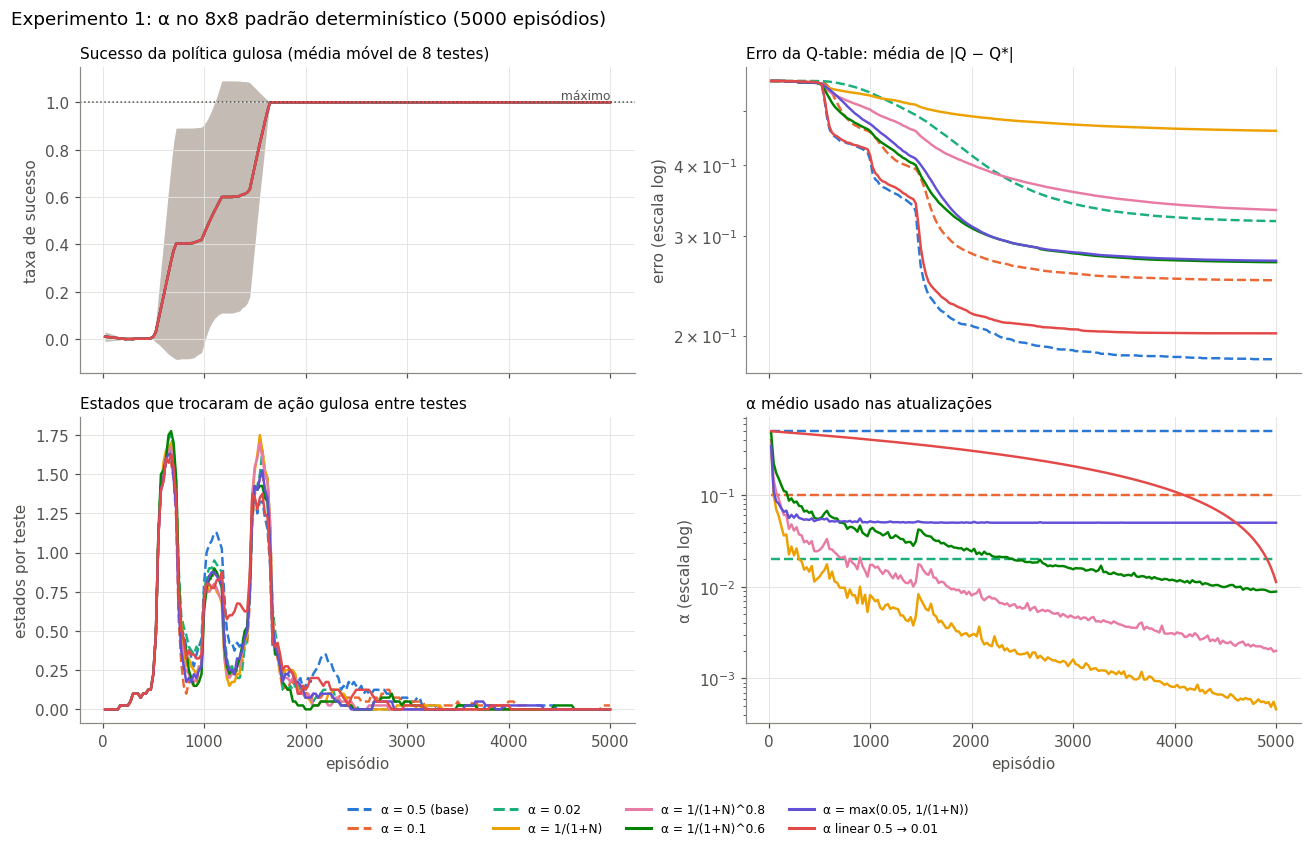

,ambiente,configuração,final,% do ótimo,teste médio,ep. até limiar,erro final |Q−Q*|,trocas (últ. 20%),acordo com π*
0,8x8 padrão determinístico,α = 0.5 (base),1.000 ± 0.000,100.0,0.806,1010 (5/5),0.1817,0.0,0.585
1,8x8 padrão determinístico,α = 0.1,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2506,0.0,0.509
2,8x8 padrão determinístico,α = 0.02,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.3189,0.0,0.498
3,8x8 padrão determinístico,α = 1/(1+N),1.000 ± 0.000,100.0,0.806,1010 (5/5),0.4606,0.0,0.555
4,8x8 padrão determinístico,α = 1/(1+N)^0.8,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.3336,0.0,0.513
5,8x8 padrão determinístico,α = 1/(1+N)^0.6,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2697,0.0,0.460
6,8x8 padrão determinístico,"α = max(0.05, 1/(1+N))",1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2714,0.0,0.475
7,8x8 padrão determinístico,α linear 0.5 → 0.01,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2019,0.0,0.581


In [7]:
amb = "8x8 padrão determinístico"
plot_curvas(runs_de(amb), f"Experimento 1: α no {amb} (5000 episódios)", "exp1_deterministico", 1.0)
tabela(amb)

## 7. Experimento 2: 8x8 padrão escorregadio

O caso principal: 20000 episódios no gelo escorregadio.

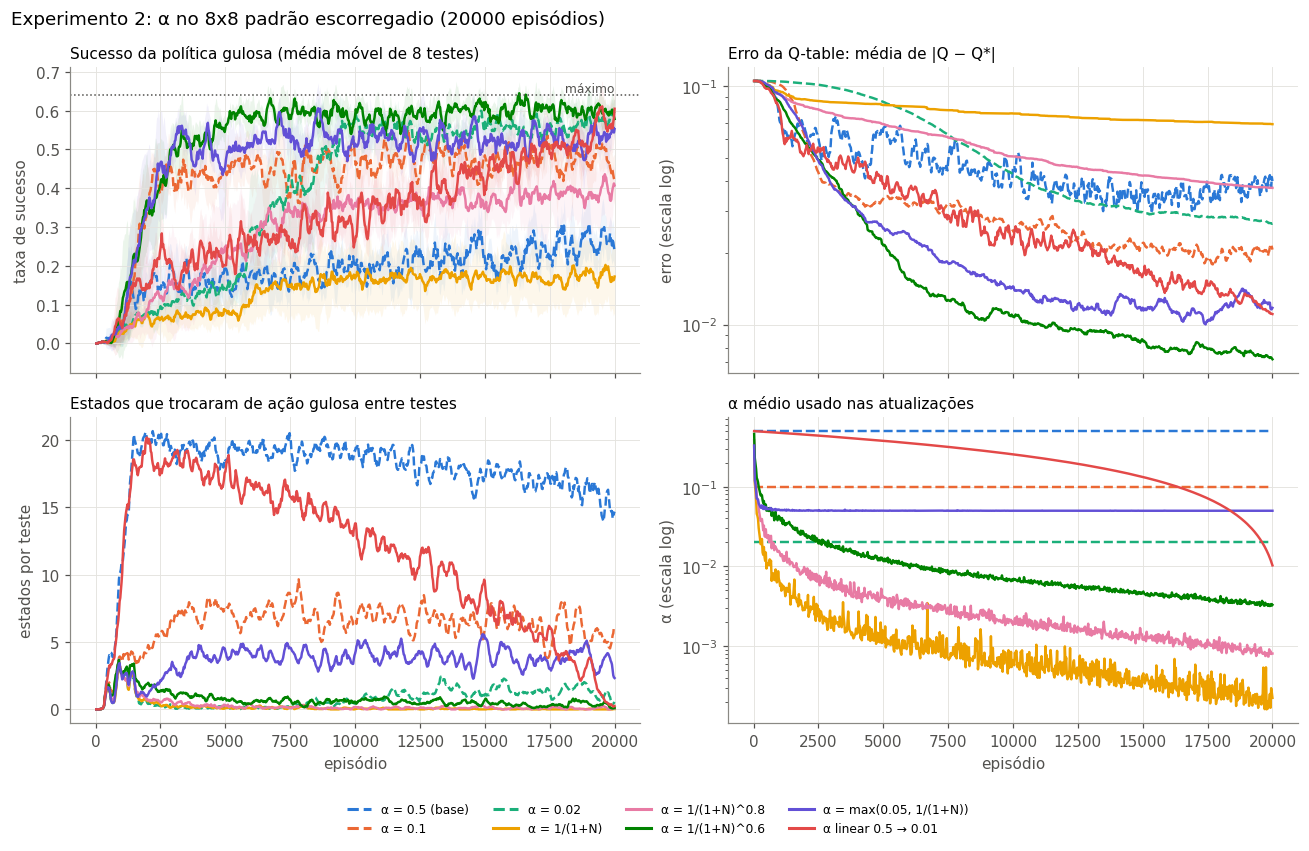

,ambiente,configuração,final,% do ótimo,teste médio,ep. até limiar,erro final |Q−Q*|,trocas (últ. 20%),acordo com π*
0,8x8 padrão escorregadio,α = 0.5 (base),0.221 ± 0.127,34.5,0.191,1620 (5/5),0.0400,16.48,0.713
1,8x8 padrão escorregadio,α = 0.1,0.512 ± 0.082,79.9,0.428,1640 (5/5),0.0206,5.94,0.838
2,8x8 padrão escorregadio,α = 0.02,0.542 ± 0.035,84.6,0.395,5455 (5/5),0.0266,1.26,0.758
3,8x8 padrão escorregadio,α = 1/(1+N),0.182 ± 0.093,28.3,0.135,6583 (3/5),0.0693,0.01,0.555
4,8x8 padrão escorregadio,α = 1/(1+N)^0.8,0.377 ± 0.075,58.9,0.295,3760 (5/5),0.0375,0.08,0.645
5,8x8 padrão escorregadio,α = 1/(1+N)^0.6,0.588 ± 0.022,91.7,0.534,1505 (5/5),0.0072,0.34,0.921
6,8x8 padrão escorregadio,"α = max(0.05, 1/(1+N))",0.553 ± 0.062,86.3,0.480,1740 (5/5),0.0118,3.62,0.853
7,8x8 padrão escorregadio,α linear 0.5 → 0.01,0.593 ± 0.016,92.5,0.334,1365 (5/5),0.0111,3.85,0.925


In [8]:
amb = "8x8 padrão escorregadio"
plot_curvas(runs_de(amb), f"Experimento 2: α no {amb} (20000 episódios)", "exp2_escorregadio_padrao", OTIMO[amb])
tabela(amb)

## 8. Experimento 3: segundo mapa escorregadio (8x8, p = 0.8)

O mesmo experimento num mapa com mais buracos, para ver se a ordem entre as configurações se mantém.

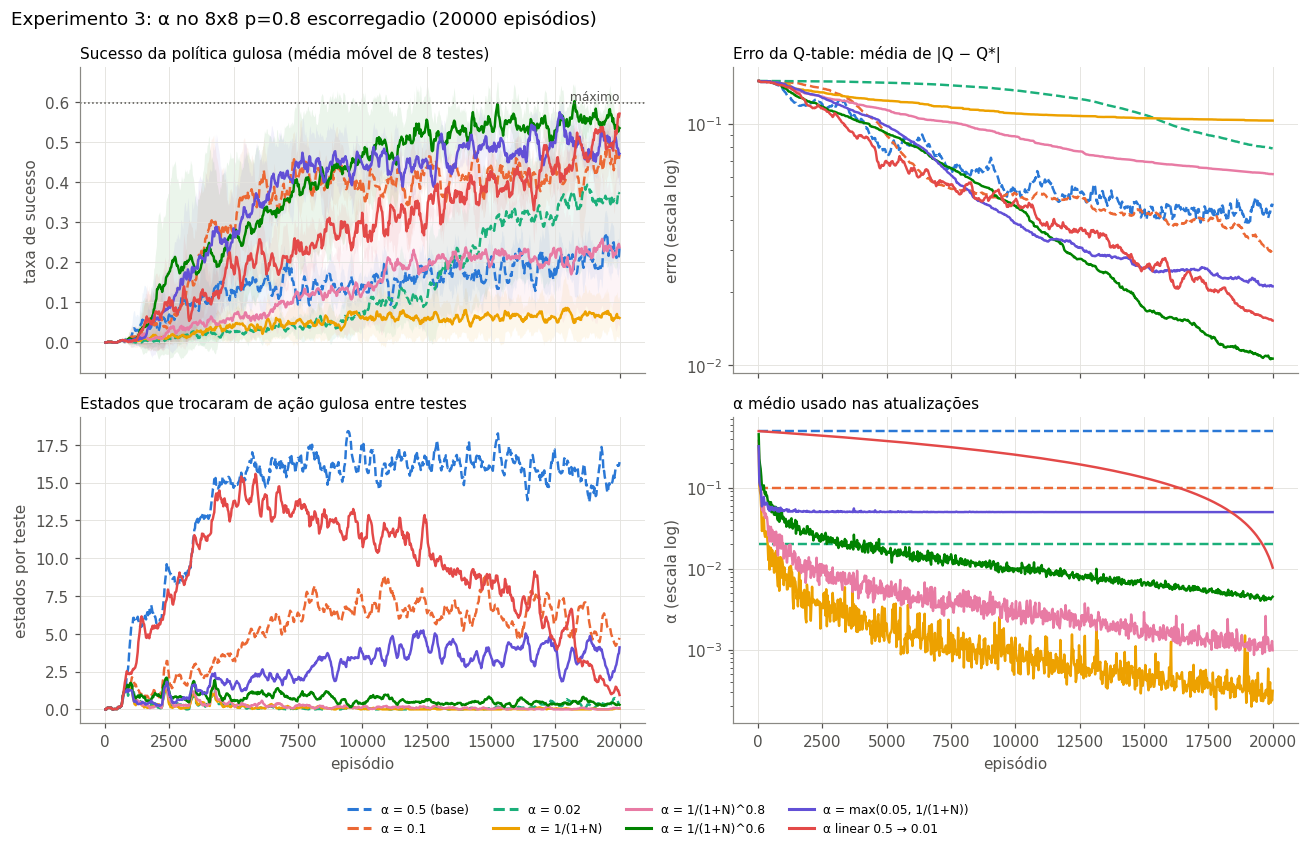

,ambiente,configuração,final,% do ótimo,teste médio,ep. até limiar,erro final |Q−Q*|,trocas (últ. 20%),acordo com π*
0,8x8 p=0.8 escorregadio,α = 0.5 (base),0.250 ± 0.138,41.8,0.144,3585 (5/5),0.0466,15.58,0.716
1,8x8 p=0.8 escorregadio,α = 0.1,0.447 ± 0.054,74.8,0.336,3880 (5/5),0.0299,6.02,0.840
2,8x8 p=0.8 escorregadio,α = 0.02,0.390 ± 0.169,65.3,0.138,13481 (4/5),0.0791,0.32,0.652
3,8x8 p=0.8 escorregadio,α = 1/(1+N),0.065 ± 0.046,10.9,0.049,9375 (1/5),0.1029,0.03,0.496
4,8x8 p=0.8 escorregadio,α = 1/(1+N)^0.8,0.217 ± 0.147,36.3,0.136,9475 (3/5),0.0618,0.04,0.664
5,8x8 p=0.8 escorregadio,α = 1/(1+N)^0.6,0.550 ± 0.030,92.1,0.391,4905 (5/5),0.0106,0.43,0.928
6,8x8 p=0.8 escorregadio,"α = max(0.05, 1/(1+N))",0.465 ± 0.089,77.9,0.369,4005 (5/5),0.0212,3.62,0.828
7,8x8 p=0.8 escorregadio,α linear 0.5 → 0.01,0.561 ± 0.026,93.9,0.276,3385 (5/5),0.0153,4.31,0.912


In [9]:
amb = "8x8 p=0.8 escorregadio"
plot_curvas(runs_de(amb), f"Experimento 3: α no {amb} (20000 episódios)", "exp3_escorregadio_p08", OTIMO[amb])
tabela(amb)

## 9. Experimento 4: as políticas aprendidas

Política gulosa final (semente 0) no 8x8 padrão escorregadio, para a base, o melhor α constante e a melhor programação
decrescente (escolhidos pelo sucesso final médio), comparadas com a política ótima de Q\*.

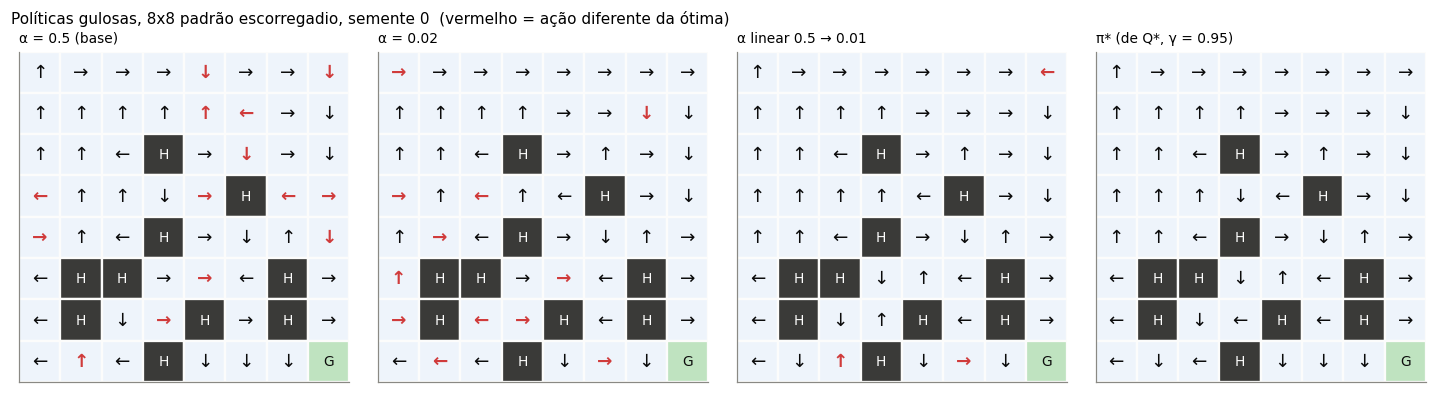

melhor constante: α = 0.02 | melhor decrescente: α linear 0.5 → 0.01


In [10]:
amb = "8x8 padrão escorregadio"
df = pd.DataFrame(TABELA)
df = df[df["ambiente"] == amb]
melhor_const = df[df["configuração"].isin(CONSTANTES)].sort_values("_final_media").iloc[-1]["configuração"]
melhor_decr = df[~df["configuração"].isin(CONSTANTES)].sort_values("_final_media").iloc[-1]["configuração"]
escolhidas = list(dict.fromkeys(["α = 0.5 (base)", melhor_const, melhor_decr]))
qs = [RUNS[(amb, r)][0]["q_table"] for r in escolhidas] + [QSTAR[amb]]
plot_politicas(qs, MAPA_PADRAO, escolhidas + ["π* (de Q*, γ = 0.95)"], f"Políticas gulosas, {amb}, semente 0",
               "exp4_politicas", QSTAR[amb])
print("melhor constante:", melhor_const, "| melhor decrescente:", melhor_decr)

Quantas vezes cada par (s, a) foi atualizado (média das sementes, base, 8x8 padrão escorregadio). Mostra por que uma
taxa **por par** é diferente de uma taxa **global**: os pares do início do mapa recebem centenas de vezes mais
atualizações que os do fundo.

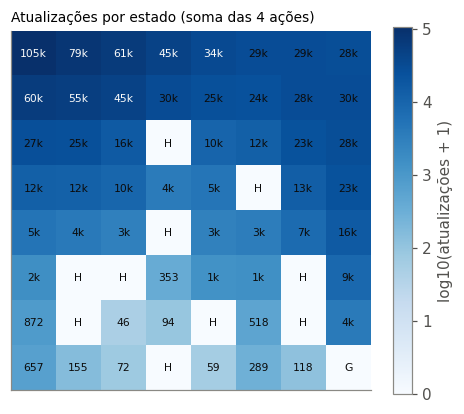

In [11]:
v = np.mean([r["visitas"] for r in RUNS[("8x8 padrão escorregadio", "α = 0.5 (base)")]], axis=0).sum(1).reshape(8, 8)
fig, ax = plt.subplots(figsize=(4.4, 3.8))
im = ax.imshow(np.log10(v + 1), cmap="Blues")
for i in range(8):
    for j in range(8):
        c = MAPA_PADRAO[i][j]
        ax.text(j, i, c if c in "HG" else f"{v[i, j]/1000:.0f}k" if v[i, j] >= 1000 else f"{v[i, j]:.0f}",
                ha="center", va="center", fontsize=7, color="#0b0b0b" if v[i, j] < 3e4 else "#fcfcfb")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(im, ax=ax, label="log10(atualizações + 1)")
ax.set_title("Atualizações por estado (soma das 4 ações)", fontsize=9, loc="left")
fig.tight_layout(); fig.savefig("figuras/exp4_visitas.png", bbox_inches="tight"); plt.show()

## 10. Tabela geral

In [12]:
geral = tabela()
geral.to_csv("resultados_luisa.csv", index=False)
geral

,ambiente,configuração,final,% do ótimo,teste médio,ep. até limiar,erro final |Q−Q*|,trocas (últ. 20%),acordo com π*
0,8x8 padrão determinístico,α = 0.5 (base),1.000 ± 0.000,100.0,0.806,1010 (5/5),0.1817,0.00,0.585
1,8x8 padrão determinístico,α = 0.1,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2506,0.00,0.509
2,8x8 padrão determinístico,α = 0.02,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.3189,0.00,0.498
3,8x8 padrão determinístico,α = 1/(1+N),1.000 ± 0.000,100.0,0.806,1010 (5/5),0.4606,0.00,0.555
4,8x8 padrão determinístico,α = 1/(1+N)^0.8,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.3336,0.00,0.513
5,8x8 padrão determinístico,α = 1/(1+N)^0.6,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2697,0.00,0.460
6,8x8 padrão determinístico,"α = max(0.05, 1/(1+N))",1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2714,0.00,0.475
7,8x8 padrão determinístico,α linear 0.5 → 0.01,1.000 ± 0.000,100.0,0.806,1010 (5/5),0.2019,0.00,0.581
8,8x8 padrão escorregadio,α = 0.5 (base),0.221 ± 0.127,34.5,0.191,1620 (5/5),0.0400,16.48,0.713
9,8x8 padrão escorregadio,α = 0.1,0.512 ± 0.082,79.9,0.428,1640 (5/5),0.0206,5.94,0.838


## 11. Discussão

**Determinístico (Experimento 1).** Todas as programações de α chegaram a 100% de sucesso, e no mesmo episódio (1010).
Até o agente achar o `G` pela primeira vez a Q-table é toda zero, e depois disso qualquer α > 0 deixa positivas as mesmas
ações; com as mesmas sementes, as decisões são idênticas. Sem ruído de transição, α decrescente não tem o que corrigir. Pelo
contrário: o erro contra Q\* ficou **maior** com 1/(1+N) (0.46 contra 0.18 da base), porque α cai antes de o valor do `G`
terminar de se propagar até o início do mapa.

**Escorregadio (Experimentos 2 e 3).** Aqui α decide o resultado, e o padrão se repetiu nos dois mapas:

| | 8x8 padrão | 8x8 p=0.8 |
|---|---|---|
| α = 0.5 (base) | 34% do ótimo, ~16 estados trocando de ação por teste no fim | 42%, ~16 trocas |
| melhor α constante | 0.02: 85%, mas só passa de 40% no episódio ~5500 | 0.1: 75% |
| α = 1/(1+N) | **28%** | **11%** |
| α = 1/(1+N)^0.6 | **92%**, erro \|Q−Q\*\| 5× menor que a base, < 1 troca por teste | **92%** |
| α linear 0.5 → 0.01 | **93%**, mas teste médio bem menor (0.33 contra 0.53) | **94%** |

1. **α constante alto nunca estabiliza.** Com α = 0.5, cada escorregão reescreve metade do valor do par: a política gulosa
   troca de ação em 15 a 20 estados a cada 25 episódios, do início ao fim. Treinar mais não adianta.
2. **α constante pequeno estabiliza, mas devagar.** α = 0.02 foi bem no mapa padrão e falhou no p=0.8 (uma semente nem
   chegou a 40%): com o mesmo passo pequeno desde o começo, a informação do `G` demora para chegar ao início do mapa.
3. **Decair rápido demais congela a tabela errada.** α = 1/(1+N) é a média simples dos alvos, e por isso parece a escolha
   "correta"; mas os primeiros alvos foram calculados com a Q-table ainda zerada e pesam o mesmo que os últimos. O gráfico de
   α mostra que em ~2500 episódios a taxa já está em 10⁻³ nos pares mais visitados. A política **para de mudar** (0.01 troca
   por teste) sem ter convergido (o maior erro contra Q\*). Estabilidade sem convergência. Isso bate com a análise de
   Even-Dar e Mansour (2003): com taxa 1/N o Q-learning pode precisar de um número de passos exponencial em 1/(1−γ); com
   taxa polinomial 1/N^ω, 1/2 < ω < 1, a dependência é polinomial.
4. **Decair devagar e por par foi o melhor.** 1/(1+N)^0.6 aprendeu rápido no começo (α perto de 1 nas primeiras visitas),
   teve o menor erro contra Q\*, a política mais parecida com π\* (92% dos estados) e quase nenhuma troca no fim. É a
   programação que melhor cumpre o que a teoria pede.
5. **O decaimento linear por episódio chega no mesmo lugar, por outro caminho.** Ele se comporta como α = 0.5 durante boa
   parte do treino (oscilando) e só estabiliza no fim, quando α fica pequeno. O resultado final é tão bom quanto o de
   1/(1+N)^0.6, mas o teste médio é muito menor e o resultado depende de saber de antemão quantos episódios haverá.
6. **O piso (max(0.05, 1/(1+N))) resolve o congelamento** do 1/(1+N), de 28% para 86%, mas a política continua trocando
   ~3,6 estados por teste: com α fixo em 0.05 ela nunca para de oscilar. É um meio-termo entre constante e decrescente.

**Por que por par.** O mapa de visitas mostra que o estado inicial recebe ~10⁵ atualizações e os do fundo do mapa, menos de
100. Uma taxa por par (modo `visitas`) dá passo grande onde há pouca informação e passo pequeno onde há muita; a taxa global
por episódio dá o mesmo passo para todos.

**Limitações.** 5 sementes por configuração; um único γ (0.95) e uma única exploração; 20000 episódios. O Q\* usado é o
do problema descontado: a política ótima com γ = 0.95 não é exatamente a de maior taxa de sucesso, e por isso nenhuma
configuração chegaria a 100% do ótimo de sucesso mesmo com a Q-table perfeita.

## 12. Conclusões

- Em ambiente determinístico, a programação de α não importa para a política final.
- No gelo escorregadio, α decrescente **por visitas com ω = 0.6** foi a melhor escolha nos dois mapas: ~92% do sucesso
  máximo, contra 34–42% da configuração base, com a Q-table convergindo para Q\* e a política estável.
- O ritmo do decaimento importa mais do que decair ou não: 1/(1+N), a escolha "de livro", foi **pior que a base**, porque
  congela a tabela cedo demais.
- Medir só o sucesso esconde isso: o erro contra Q\* e as trocas de ação separam "parou de mudar" de "convergiu".